# Spotting Poor Households for Welfare Targeting in Sri Lanka
### Applied Machine Learning assignment - HIES 2019 proxy-means-test model

**Problem.** Sri Lanka's poverty-targeted cash transfers (Samurdhi, now Aswesuma) must decide which households
are poor without being able to verify income. This notebook builds a model that predicts whether a household's
per-capita expenditure falls below the official poverty line using only characteristics a field officer can
observe - location, demographics, education, housing, assets, land and access to services.

**Data.** Department of Census and Statistics (DCS), Household Income and Expenditure Survey 2019,
19,911 households, all 25 districts.

**Pipeline.** `src/poverty/` holds the reusable code; the heavy steps run as scripts
(`scripts/eda.py -> tune.py -> train.py -> explain.py`) and this notebook walks through the results.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, joblib
from IPython.display import Image, display
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
from poverty.data import load, split, xyw
from poverty.features import feature_lists
FIG, TAB = ROOT/'reports'/'figures', ROOT/'reports'/'tables'
show = lambda f, w=820: display(Image(filename=str(FIG/f), width=w))

## 1. Know the dataset

In [2]:
df = load()
feats, nums, cats = feature_lists(df)
print(df.shape, '| features:', len(feats), f'({len(nums)} numeric, {len(cats)} categorical)')
pd.read_csv(TAB/'dataset_summary.csv', index_col=0).round(2)

(19911, 107) | features: 93 (77 numeric, 16 categorical)


,value
Households (sample),19911.00
Persons (sample),74285.00
Districts,25.00
PSUs (clusters),2411.00
Features used,93.00
Numeric,77.00
Categorical,16.00
"Poor households, unweighted %",12.54
"Poor households, weighted %",11.61
"Poor persons (headcount), weighted %",13.92


In [3]:
df[['district_name','sector_name','n_members','head_edu_yrs','house_type','cooking_fuel',
    'asset_types_owned','pce','poor','finalweight']].head()

,district_name,sector_name,n_members,head_edu_yrs,house_type,cooking_fuel,asset_types_owned,pce,poor,finalweight
0,Colombo,Urban,4,10.0,Single house 1 floor,LP gas,13,16510.382750,0,392.442535
1,Colombo,Urban,6,4.0,Single house 1 floor,LP gas,9,19770.723333,0,392.442535
2,Colombo,Urban,6,7.0,Single house 1 floor,LP gas,6,13890.584667,0,392.442535
3,Colombo,Urban,7,7.0,Single house 1 floor,LP gas,8,18406.145714,0,392.442535
4,Colombo,Urban,4,13.0,Single house 1 floor,Firewood,11,38698.755000,0,392.442535


**Data-quality checks performed in `features.py`**
* All household tables join 1:1 on `psu + snumber + hhno` (no duplicates, no unmatched rows).
* The person file lists 5,311 *non-usual* residents; keeping usual residents reproduces DCS `hhsize` for 100% of households.
* Unknown/refused answers use codes 8/9/99 - mapped to labelled levels, never treated as numbers.
* Heavy skew (PCE skewness 12, income 15) -> log scale for analysis; Yeo-Johnson for linear/KNN/SVM models.
* Missingness is tiny (max 1.5%, distance to government dispensary) -> median imputation inside the pipeline.

In [4]:
pd.read_csv(TAB/'missing_values.csv', index_col=0).T

,max_edu_yrs,mean_adult_edu_yrs,head_edu_yrs,bedrooms,floor_area_band,km_to_bus_halt,km_to_primary_school,km_to_secondary_school,km_to_hospital,km_to_govt_dispensary,km_to_ds_office,km_to_bank,km_to_post_office,km_to_agrarian_office,persons_per_bedroom
missing_%,0.005,0.03,0.04,0.015,0.015,0.04,0.181,0.1,0.04,1.487,0.055,0.04,0.045,0.07,0.015


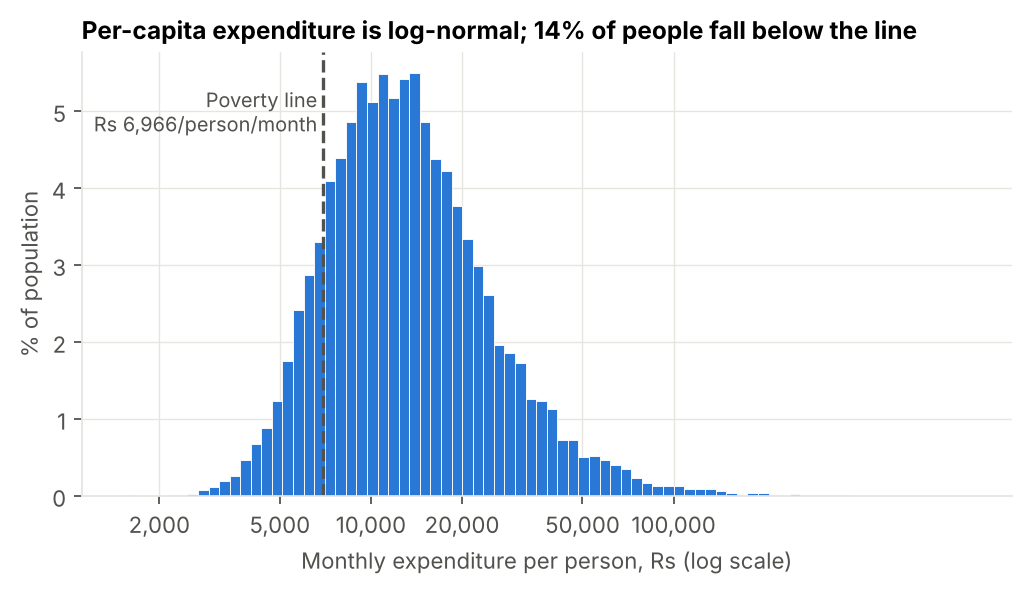

In [5]:
show('fig01_pce_distribution.png')

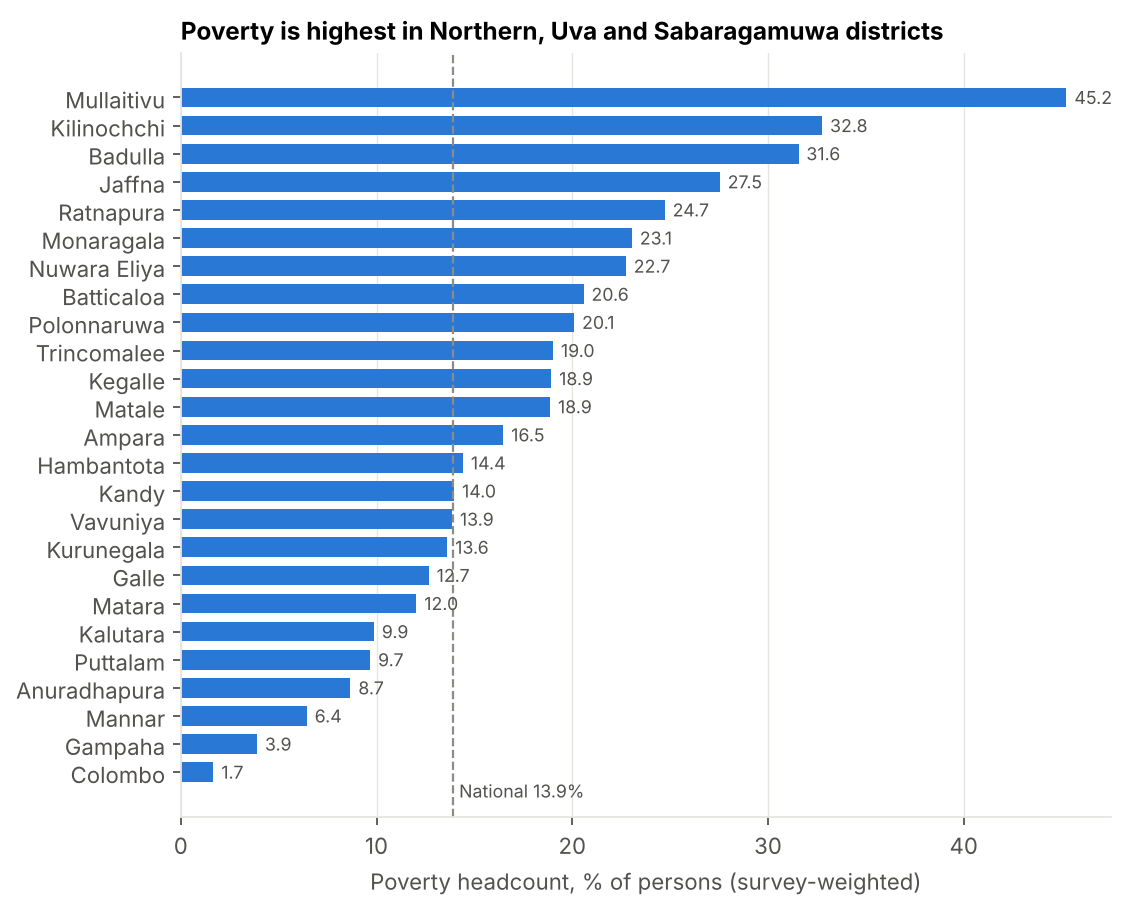

In [6]:
show('fig02_poverty_by_district.png', 700)

In [7]:
pd.read_csv(TAB/'poverty_by_sector.csv')

,sector_name,households,poverty_rate_hh_w,headcount_w,samurdhi_coverage_w
0,Estate,849.0,27.28,31.18,9.56
1,Rural,15858.0,12.36,14.73,22.99
2,Urban,3204.0,4.13,5.65,11.13


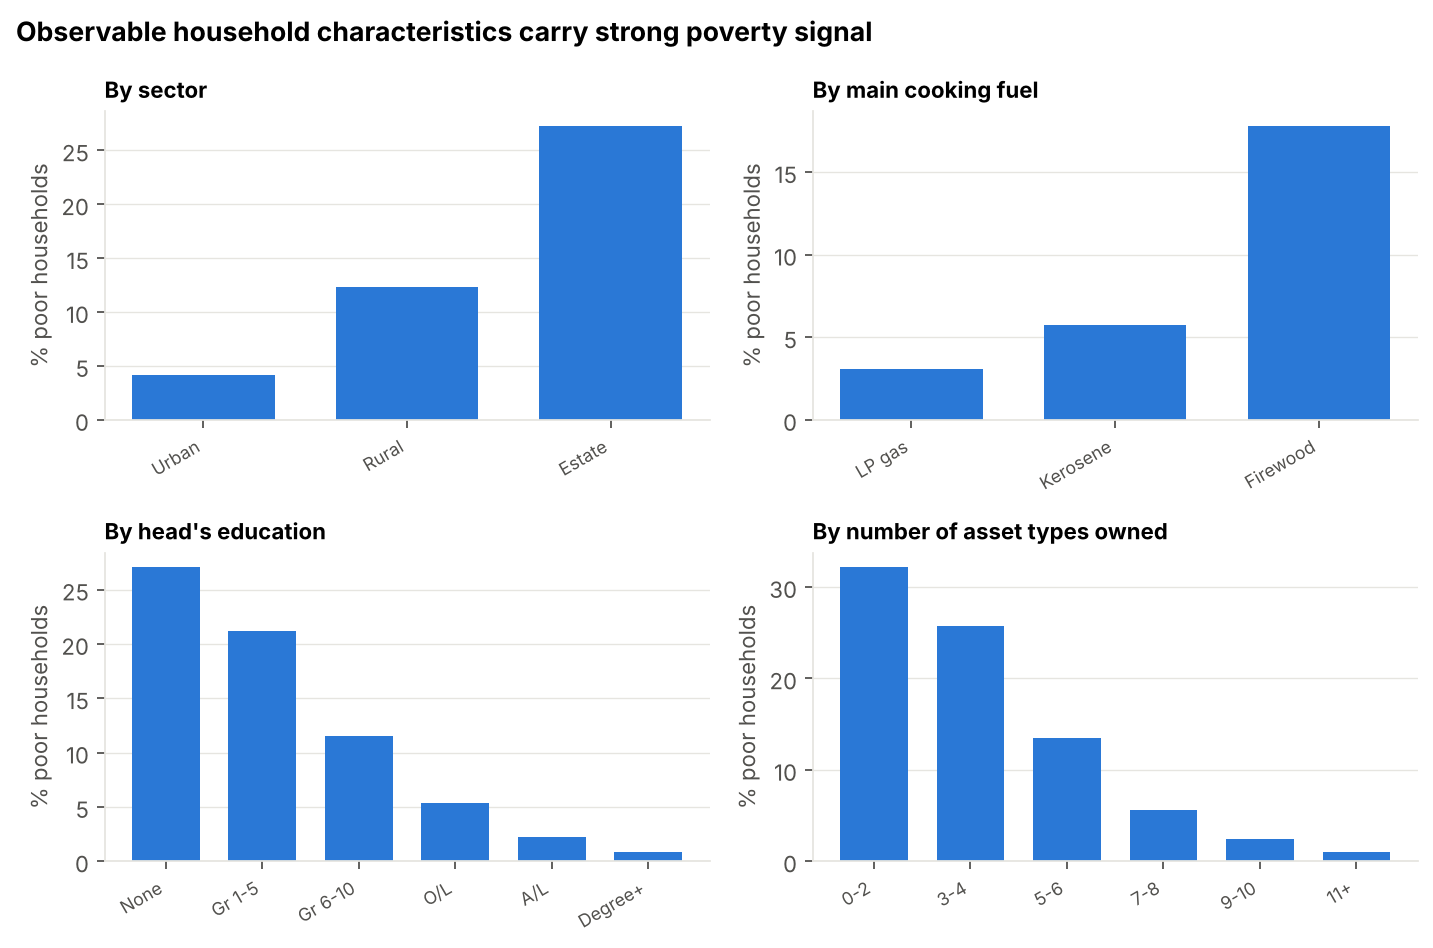

In [8]:
show('fig03_poverty_correlates.png')

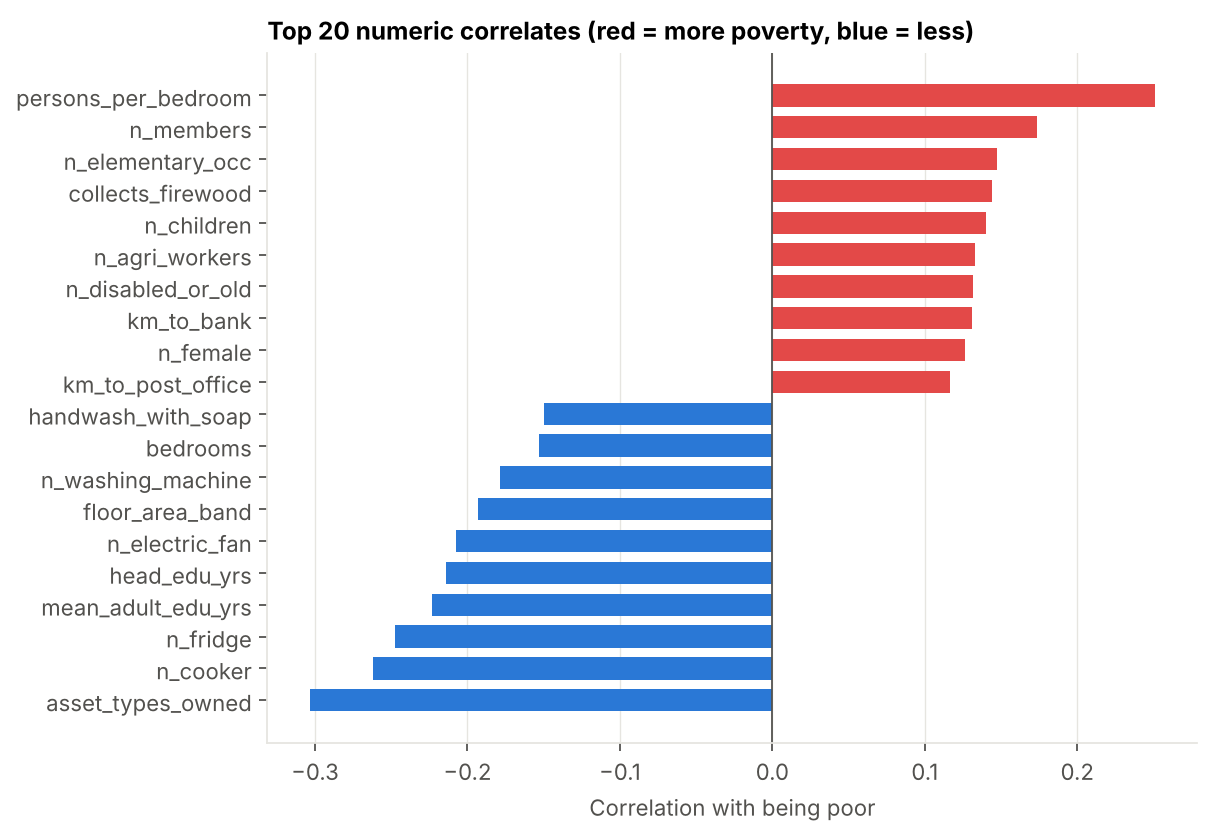

In [9]:
show('fig04_numeric_correlations.png', 700)

## 2. Problem framing and leakage control
* **Target:** `poor = 1` if monthly expenditure per person < Rs 6,966 (DCS official poverty line, 2019 base).
  Survey-weighted headcount reproduced: **13.9%** of persons (DCS published 14.3% with spatial price deflators).
* **Excluded features:** income, expenditure (they define the target), debt (self-reported), Samurdhi receipt
  (the programme being evaluated), ethnicity and religion (non-discrimination - audit only).
* **Split:** 80/20, *stratified and grouped by PSU* so neighbours from the same sampling cluster never appear in
  both train and test. All CV inside the training set is also PSU-grouped.
* **Survey weights** (`finalweight`) are used as `sample_weight` in training and in every metric.

In [10]:
tr, te = split(df)
print('train', len(tr), 'test', len(te), '| shared PSUs:', len(set(df.psu.iloc[tr]) & set(df.psu.iloc[te])))
print('poverty rate train/test:', df.poor.iloc[tr].mean().round(4), df.poor.iloc[te].mean().round(4))

train 15903 test 4008 | shared PSUs: 0
poverty rate train/test: 0.1256 0.1243


## 3. Models
| Group | Models |
|---|---|
| Existing practice | **OLS proxy-means test** - linear regression of log consumption (World Bank-style PMT used for welfare targeting) |
| Covered in lectures | Logistic Regression, Decision Tree, KNN, SVM (RBF), Random Forest, AdaBoost, Gradient Boosting, XGBoost, LightGBM, CatBoost |
| **New (not covered)** | **Explainable Boosting Machine (EBM)**, **Extra Trees**, **Balanced Random Forest**, **NGBoost**, **LightGBM PMT regressor** (probabilistic regression->classification hybrid) |
| **Proposed** | **Survey-weighted hybrid stacked ensemble**: CatBoost + LightGBM + XGBoost + EBM + Extra Trees + LightGBM-PMT + OLS-PMT, blended by a weighted logistic meta-learner on out-of-fold logits |

### 3.1 Hyperparameter design (Optuna TPE, PSU-grouped CV, objective = weighted PR-AUC)

In [11]:
bp = json.load(open(ROOT/'models'/'best_params.json'))
pd.DataFrame({k: {**v['params'], 'cv_wAP': round(v['cv_wAP'],4), 'trials': v['n_trials']} for k, v in bp.items()}).T

,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,reg_alpha,scale_pos_weight,cv_wAP,trials,max_depth,min_child_weight,gamma,max_features,min_samples_leaf,interactions,max_leaves,iterations,depth,l2_leaf_reg,random_strength,bagging_temperature
LightGBM,1400.0,0.012262,89.0,73.0,0.565337,0.334463,0.059869,0.015676,1.743912,0.5253,40.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
XGBoost,800.0,0.049877,NaN,NaN,0.664692,0.331391,6.589180,NaN,6.208882,0.5223,15.0,3.0,2.489146,4.533854,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LightGBM PMT regressor,1000.0,0.017935,30.0,14.0,0.901098,0.352185,17.564279,NaN,NaN,0.5279,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extra Trees,400.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4914,6.0,NaN,NaN,NaN,0.347757,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EBM,NaN,0.020000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.5126,5.0,NaN,NaN,NaN,NaN,50.0,0.0,3.0,NaN,NaN,NaN,NaN,NaN
CatBoost,NaN,0.035964,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.5246,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,700.0,7.0,1.607124,0.313578,0.366362


## 4. Training and evaluation

In [12]:
cv = pd.read_csv(TAB/'cv_results.csv')
cv[['model','group','ROC_AUC_mean','ROC_AUC_sd','PR_AUC_mean','PR_AUC_sd','Brier_mean']].round(4)

,model,group,ROC_AUC_mean,ROC_AUC_sd,PR_AUC_mean,PR_AUC_sd,Brier_mean
0,Stacked Ensemble (proposed),Proposed,0.8943,0.0078,0.5321,0.0249,0.0728
1,LightGBM PMT regressor,New (not covered),0.8914,0.0090,0.5227,0.0252,0.0736
2,LightGBM,Covered in lectures,0.8873,0.0051,0.5179,0.0222,0.0760
3,XGBoost,Covered in lectures,0.8861,0.0061,0.5163,0.0275,0.1115
4,Gradient Boosting,Covered in lectures,0.8828,0.0064,0.5092,0.0251,0.0756
5,CatBoost,Covered in lectures,0.8868,0.0063,0.5083,0.0269,0.0753
6,EBM,New (not covered),0.8850,0.0082,0.5065,0.0299,0.0752
7,Logistic Regression,Covered in lectures,0.8852,0.0088,0.5037,0.0358,0.1378
8,NGBoost,New (not covered),0.8801,0.0070,0.5032,0.0270,0.0769
9,OLS PMT (existing practice),Existing practice,0.8859,0.0109,0.5028,0.0314,0.0756


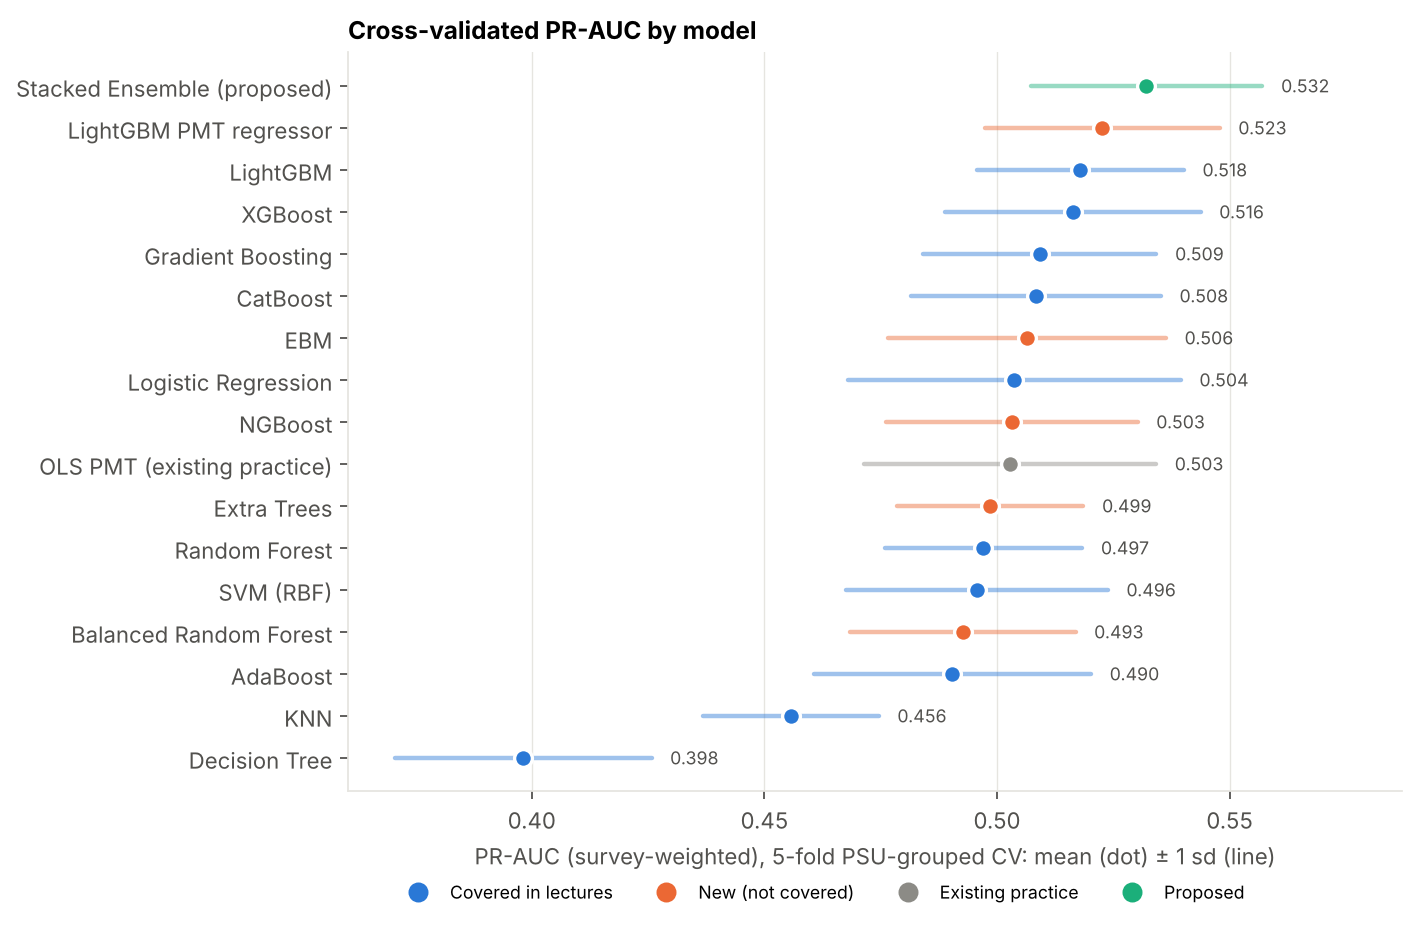

In [13]:
show('fig05_cv_pr_auc.png', 760)

In [14]:
res = pd.read_csv(TAB/'test_results.csv')
res[['model','group','ROC_AUC','PR_AUC','Recall','Precision','F1','Brier','Exclusion_err@PR','Inclusion_err@PR','train_seconds']].round(4)

,model,group,ROC_AUC,PR_AUC,Recall,Precision,F1,Brier,Exclusion_err@PR,Inclusion_err@PR,train_seconds
0,Stack of all models (ablation),Ablation,0.9088,0.5914,0.7006,0.4794,0.5692,0.0679,0.4475,0.4443,NaN
1,Stacked Ensemble (proposed),Proposed,0.9084,0.5885,0.6772,0.4965,0.5729,0.0683,0.4536,0.4497,347.2519
2,LightGBM PMT regressor,New (not covered),0.9052,0.5804,0.6757,0.4821,0.5627,0.0699,0.4575,0.4537,38.7986
3,LightGBM,Covered in lectures,0.9007,0.5694,0.6637,0.4828,0.5590,0.0707,0.4549,0.4511,38.2750
4,CatBoost,Covered in lectures,0.8992,0.5693,0.6674,0.4602,0.5448,0.0703,0.4646,0.4615,163.2884
5,OLS PMT (existing practice),Existing practice,0.8998,0.5620,0.6616,0.4590,0.5420,0.0715,0.4832,0.4804,22.7403
6,XGBoost,Covered in lectures,0.8970,0.5574,0.6830,0.4603,0.5500,0.1095,0.4760,0.4724,7.8481
7,Gradient Boosting,Covered in lectures,0.8942,0.5564,0.6488,0.4557,0.5354,0.0715,0.4649,0.4613,86.9540
8,Logistic Regression,Covered in lectures,0.8970,0.5562,0.6454,0.4664,0.5415,0.1339,0.4754,0.4718,22.4323
9,EBM,New (not covered),0.8947,0.5522,0.6549,0.4594,0.5400,0.0717,0.4657,0.4616,29.7784


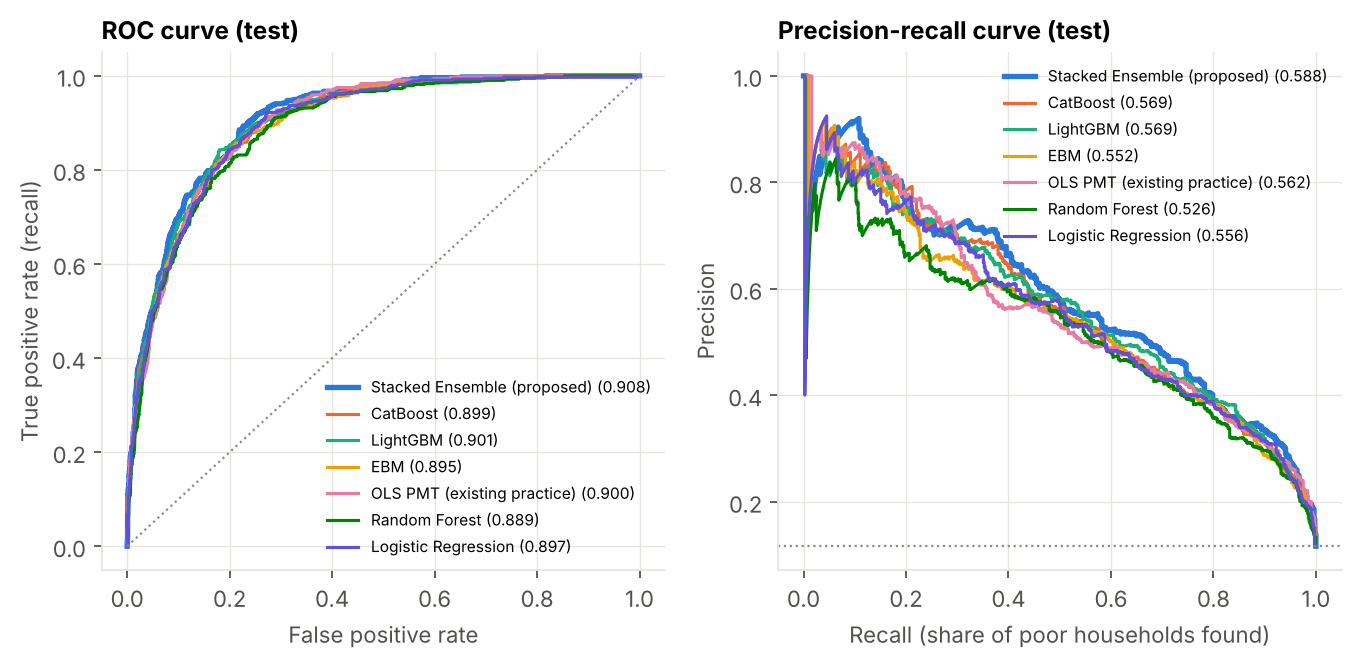

In [15]:
show('fig06_roc_pr_test.png')

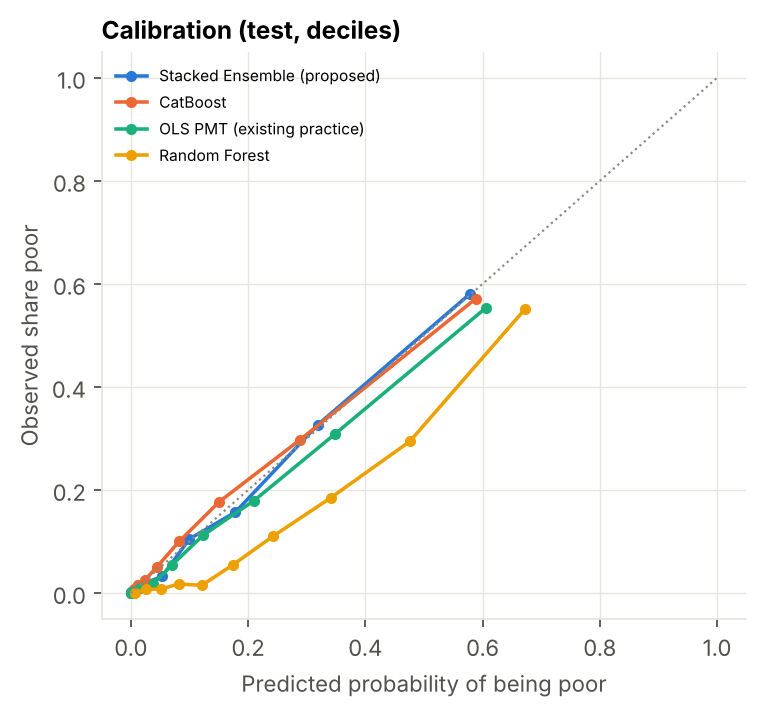

In [16]:
show('fig07_calibration.png', 520)

### 4.1 Is the improvement real? PSU-cluster bootstrap (1,000 resamples of the test set)

In [17]:
pd.read_csv(TAB/'bootstrap_ci.csv')

,metric,model,estimate,ci_low,ci_high,p_le_0
0,PR_AUC,Stacked Ensemble (proposed),0.5910,0.5356,0.6424,NaN
1,PR_AUC,LightGBM PMT regressor,0.5827,0.5283,0.6332,NaN
2,PR_AUC,OLS PMT (existing practice),0.5640,0.5134,0.6134,NaN
3,PR_AUC,Logistic Regression,0.5592,0.5063,0.6141,NaN
4,PR_AUC,Δ Stack − LightGBM PMT regressor,0.0083,-0.0033,0.0205,0.088
5,PR_AUC,Δ Stack − OLS PMT (existing practice),0.0270,0.0045,0.0546,0.008
6,PR_AUC,Δ Stack − Logistic Regression,0.0318,0.0139,0.0508,0.000
7,ROC_AUC,Stacked Ensemble (proposed),0.9083,0.8951,0.9215,NaN
8,ROC_AUC,LightGBM PMT regressor,0.9052,0.8919,0.9186,NaN
9,ROC_AUC,OLS PMT (existing practice),0.8997,0.8854,0.9131,NaN


In [18]:
pd.read_csv(TAB/'stack_meta_weights.csv')

,Unnamed: 0,meta_coef
0,CatBoost,0.110390
1,LightGBM,0.210359
2,XGBoost,-0.068168
3,EBM,0.037367
4,Extra Trees,0.089132
5,LightGBM PMT regressor,0.417786
6,OLS PMT (existing practice),0.235115


## 5. Single-sample inference with the exported pickle

In [19]:
art = joblib.load(ROOT/'models'/'poverty_model.pkl')     # the deployable artefact
sample = json.load(open(ROOT/'app'/'sample_household.json'))  # a held-out test household
X1 = pd.DataFrame([sample])[art['features']]
p = art['model'].predict_proba(X1)[:, 1][0]
print(f"P(poor) = {p:.3f}  | policy threshold (F2) = {art['threshold_f2']:.3f}  ->",
      'FLAG for support' if p >= art['threshold_f2'] else 'not flagged')
json.load(open(TAB/'single_sample_inference.json'))

P(poor) = 0.654  | policy threshold (F2) = 0.126  -> FLAG for support


{'row_in_test': 351,
 'psu': 112009,
 'predicted_probability': 0.653854675121287,
 'decision_threshold': 0.12567075274105025,
 'decision': 'Eligible (poor)',
 'actual_poor': 1,
 'actual_pce': 5956.892857142857,
 'base_learner_probabilities': {'CatBoost': 0.39886606582086576,
  'LightGBM': 0.826736801254703,
  'XGBoost': 0.7905346155166626,
  'EBM': 0.828442539306143,
  'Extra Trees': 0.6618587352036623,
  'LightGBM PMT regressor': 0.5783365995080009,
  'OLS PMT (existing practice)': 0.63142013599281},
 'top_contributions_logodds': {'n_members': 1.2109,
  'persons_per_bedroom': 0.7456,
  'asset_types_owned': 0.6653,
  'district_name': -0.4291,
  'n_disabled_or_old': 0.3502,
  'n_cooker': 0.2959,
  'n_car_van': 0.2548,
  'n_mobile_phone': -0.2478,
  'cooking_fuel': 0.2383,
  'mean_adult_edu_yrs': 0.2181}}

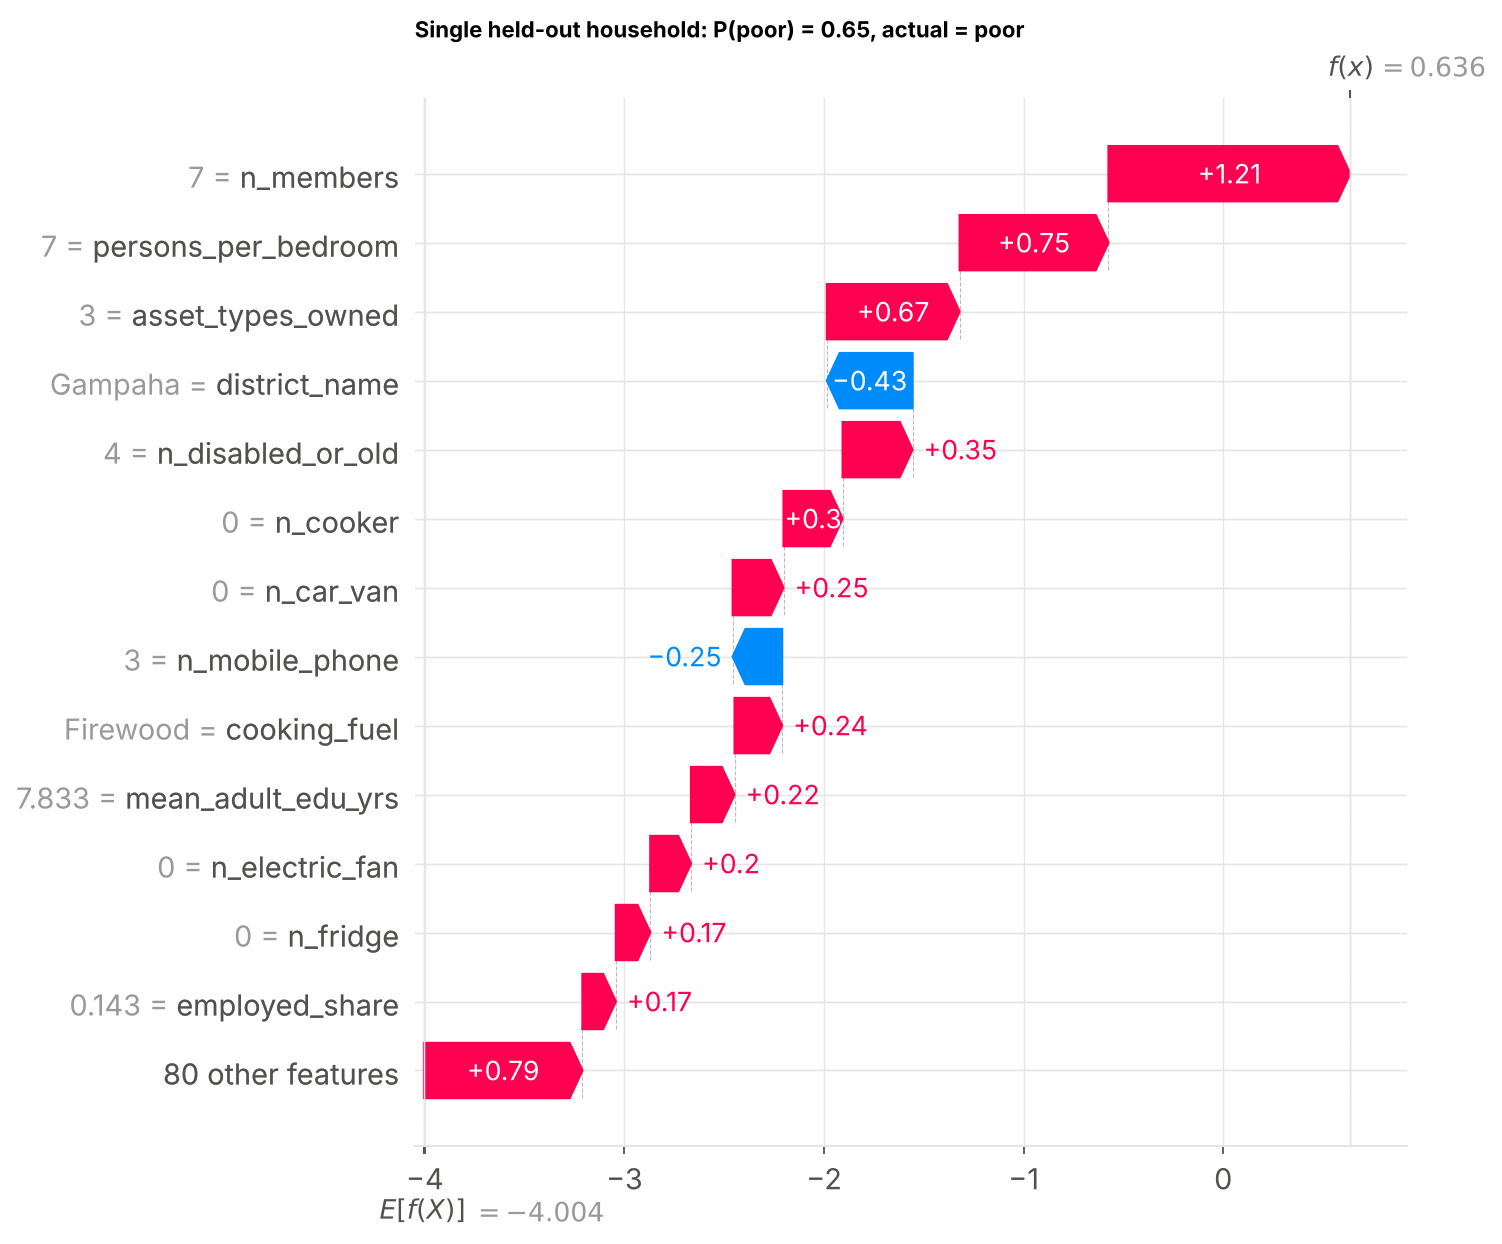

In [20]:
show('fig12_single_household_waterfall.png', 760)

## 6. Explainability

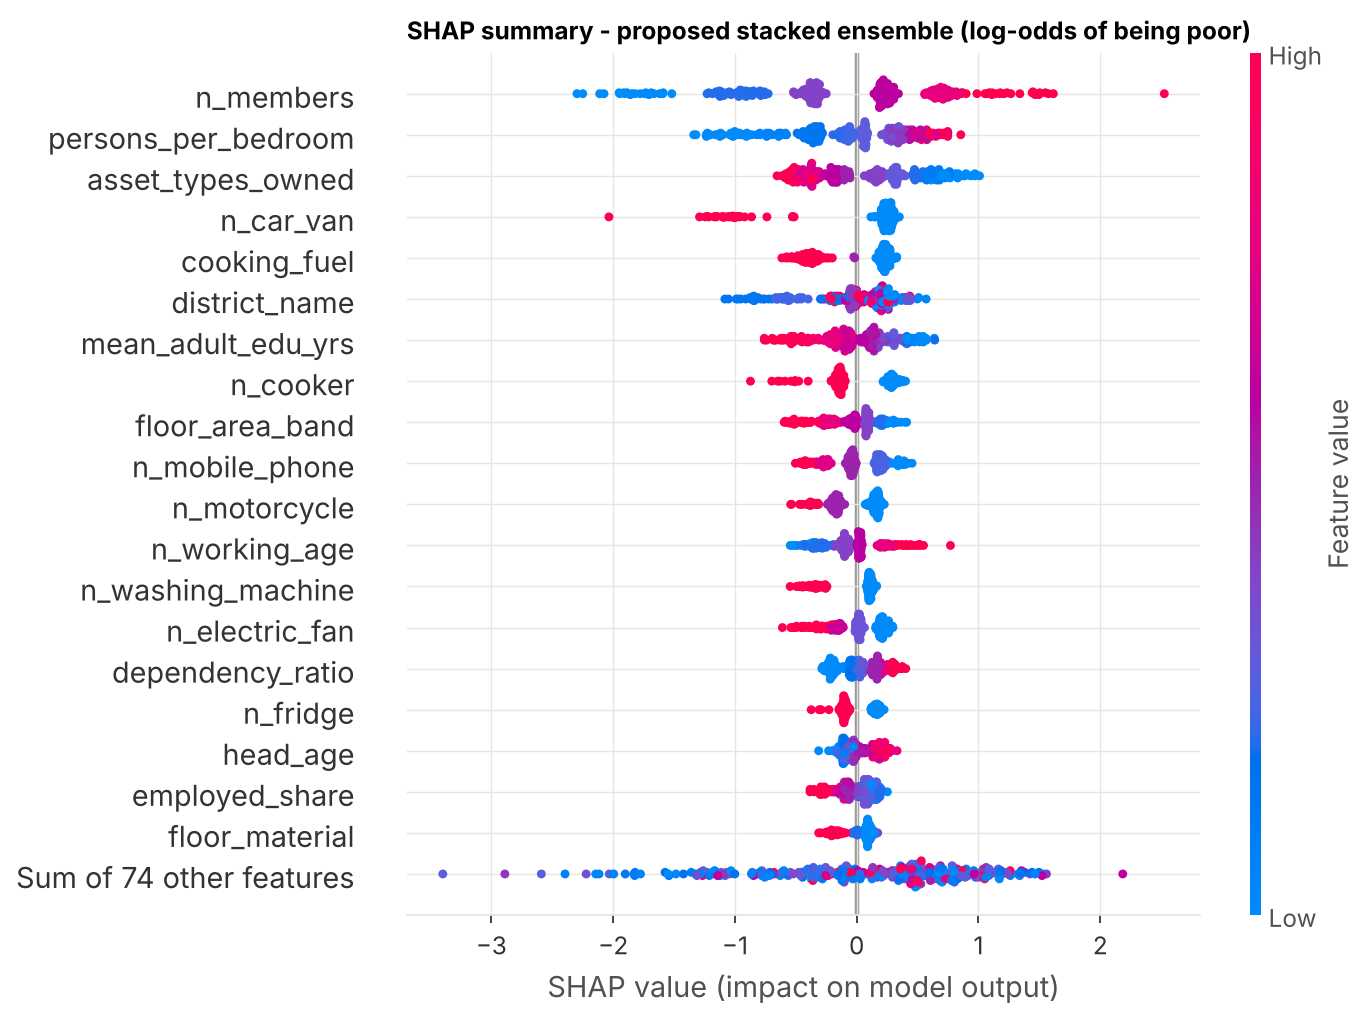

In [21]:
show('fig08_shap_beeswarm.png', 760)

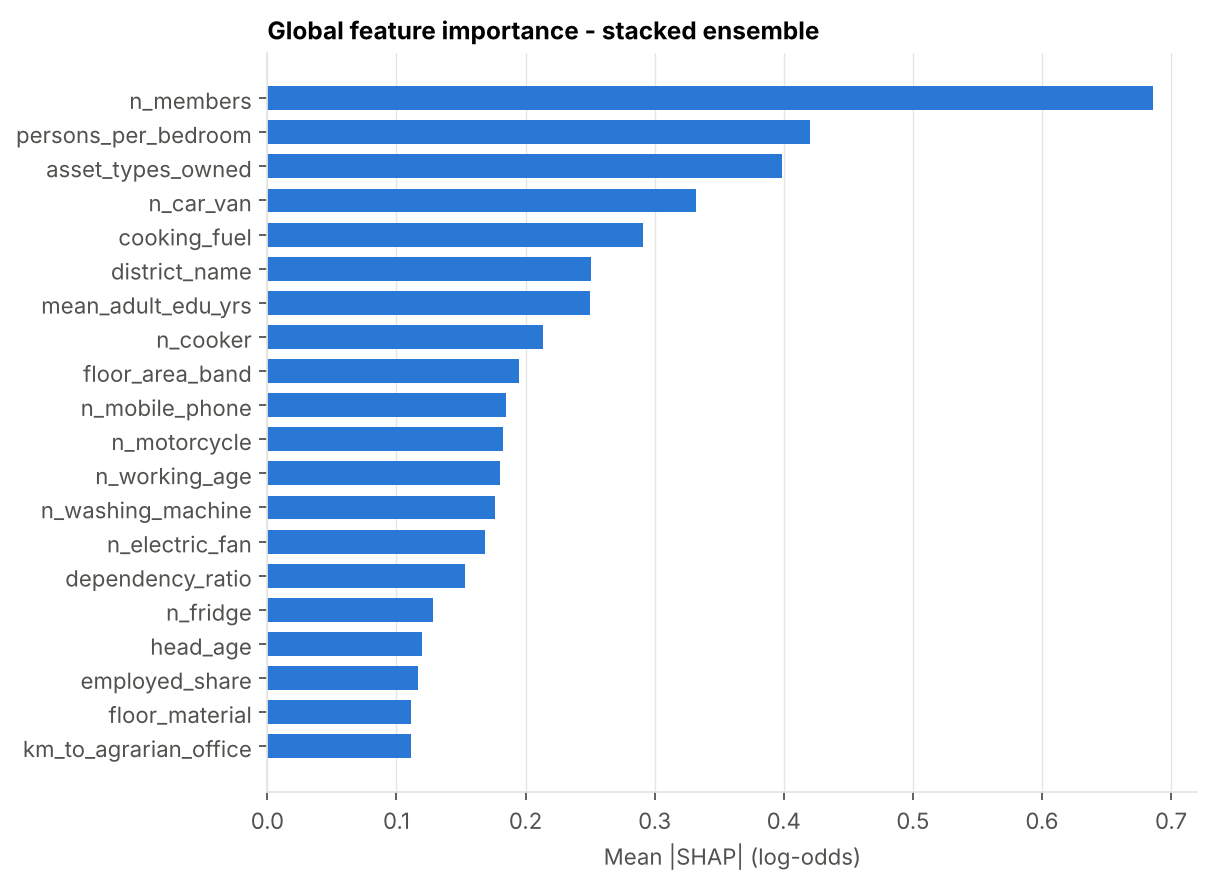

In [22]:
show('fig09_shap_bar.png', 700)

In [23]:
print(json.load(open(TAB/'importance_agreement.json')))
pd.read_csv(TAB/'importance_comparison.csv', index_col=0).head(15)

{'spearman_stack_vs_catboost_treeshap': 0.7637400312269407, 'spearman_stack_vs_native': 0.7241774424844002}


,stack_perm_SHAP,catboost_treeSHAP,catboost_native_importance,rank_stack,rank_catboost_shap,rank_native
n_members,0.6861,0.6860,11.3927,1.0,1.0,1.0
persons_per_bedroom,0.4205,0.3541,4.7271,2.0,3.0,4.0
asset_types_owned,0.3983,0.6511,9.5381,3.0,2.0,2.0
n_car_van,0.3323,0.0000,0.0000,4.0,90.0,90.0
cooking_fuel,0.2910,0.2572,2.4728,5.0,6.0,7.0
district_name,0.2508,0.3202,7.2903,6.0,4.0,3.0
mean_adult_edu_yrs,0.2502,0.2650,3.8532,7.0,5.0,5.0
n_cooker,0.2136,0.2355,2.1670,8.0,7.0,11.0
floor_area_band,0.1951,0.1310,2.1762,9.0,11.0,10.0
n_mobile_phone,0.1851,0.1985,2.3543,10.0,8.0,8.0


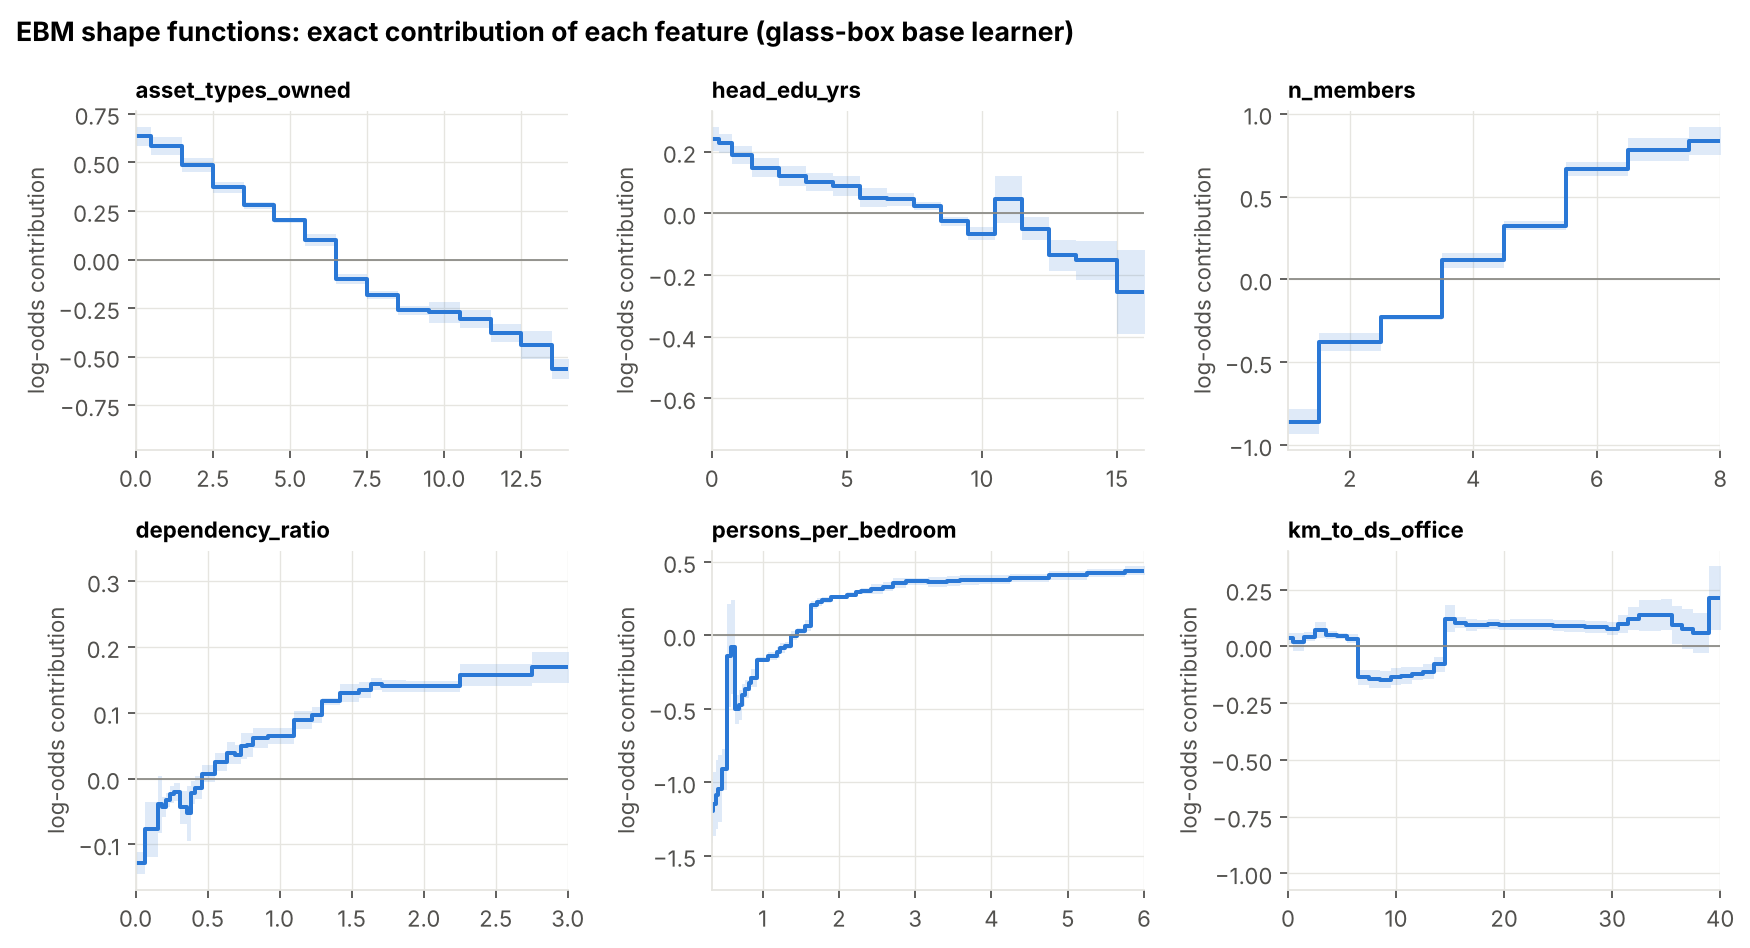

In [24]:
show('fig10_ebm_shapes.png')

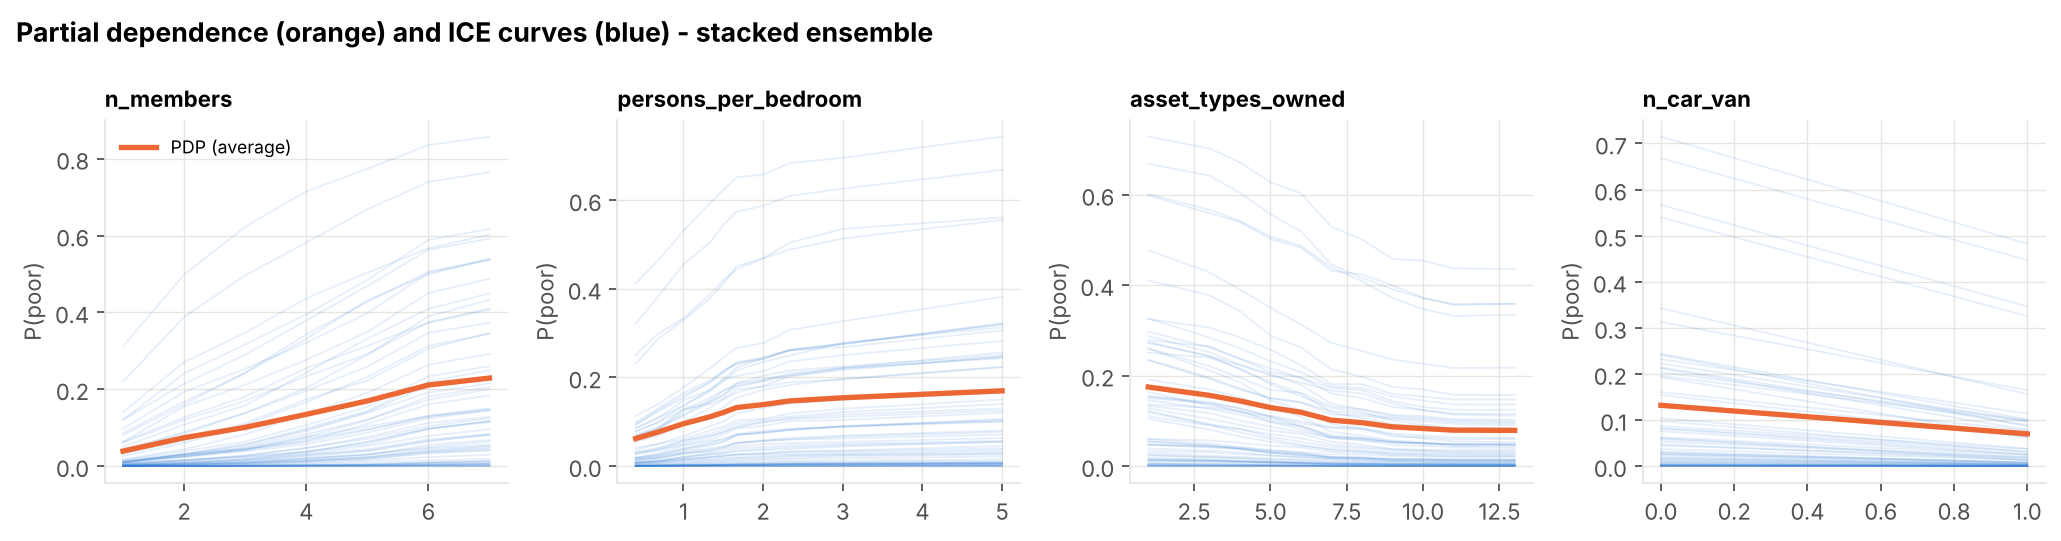

In [25]:
show('fig11_pdp_ice.png')

## 7. Critical discussion: fairness and real-world targeting

In [26]:
pd.read_csv(TAB/'fairness_audit.csv').round(3)

,attribute,group,n_households,poverty_rate,selection_rate,recall,exclusion_error,inclusion_error,ROC_AUC,mean_pred
0,sector_name,Estate,189,0.280,0.751,0.945,0.055,0.648,0.829,0.313
1,sector_name,Rural,3249,0.120,0.295,0.854,0.146,0.655,0.901,0.122
2,sector_name,Urban,570,0.051,0.093,0.754,0.246,0.585,0.961,0.043
3,province,Central,595,0.130,0.344,0.918,0.082,0.653,0.914,0.141
4,province,Eastern,310,0.163,0.412,0.882,0.118,0.651,0.846,0.170
5,province,North Central,282,0.077,0.253,0.900,0.100,0.725,0.921,0.105
6,province,North Western,342,0.084,0.254,0.765,0.235,0.748,0.875,0.098
7,province,Northern,392,0.211,0.455,0.835,0.165,0.613,0.859,0.200
8,province,Sabaragamuwa,347,0.205,0.424,0.883,0.117,0.574,0.886,0.175
9,province,Southern,567,0.087,0.260,0.785,0.215,0.737,0.874,0.100


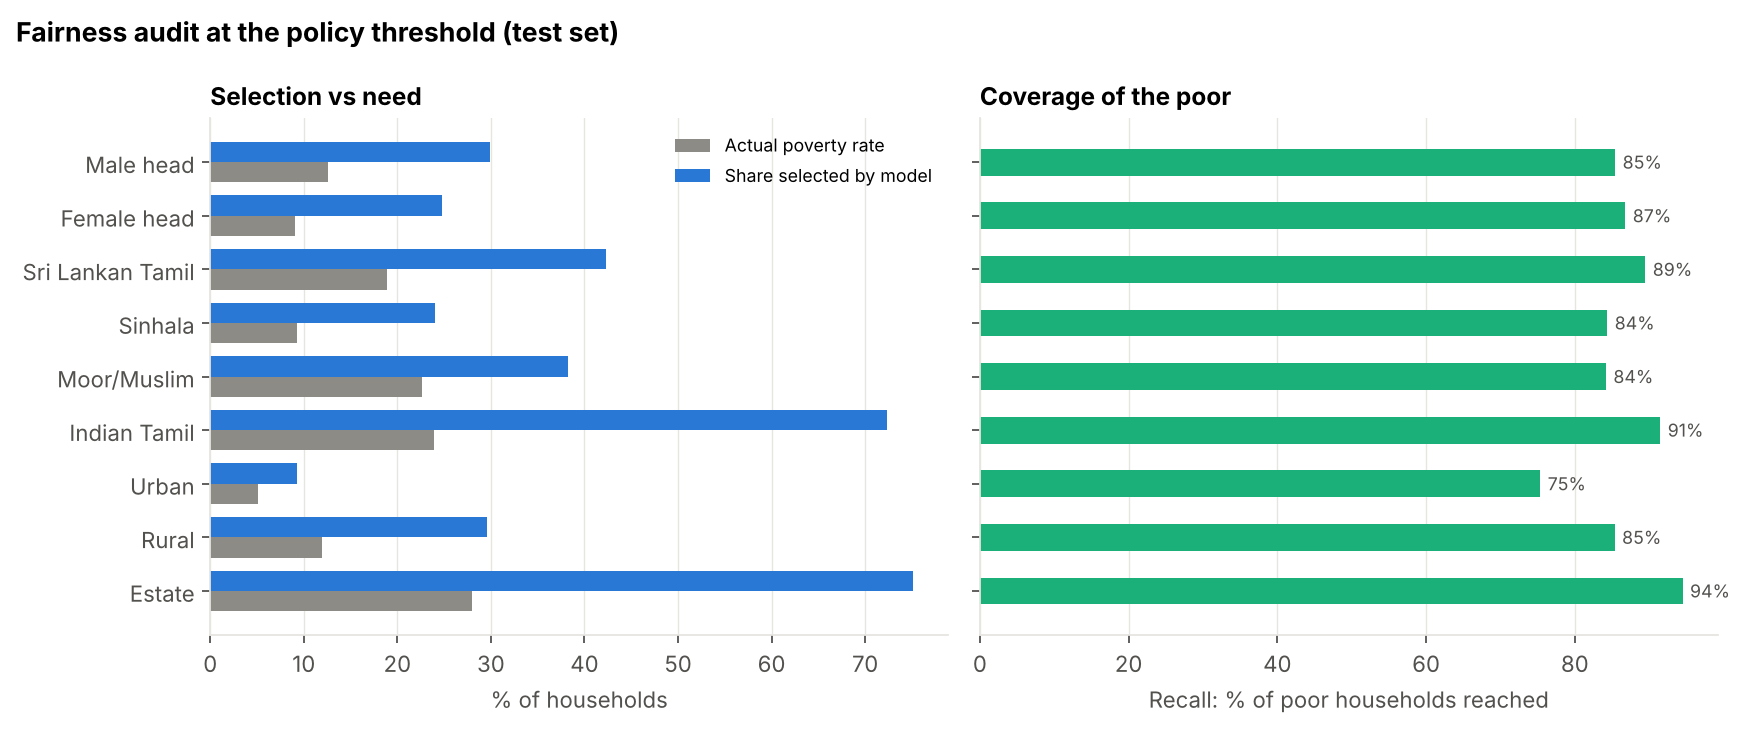

In [27]:
show('fig13_fairness.png')

In [28]:
pd.read_csv(TAB/'samurdhi_comparison.csv').round(3)

,poverty definition,rule,coverage,exclusion_error,inclusion_error
0,Post-transfer PCE (as measured),Actual Samurdhi receipt (2019),0.21,0.592,0.774
1,Post-transfer PCE (as measured),Stacked Ensemble (proposed) at same coverage,0.21,0.227,0.571
2,Post-transfer PCE (as measured),OLS PMT (existing practice) at same coverage,0.21,0.246,0.582
3,Post-transfer PCE (as measured),LightGBM PMT regressor at same coverage,0.21,0.242,0.580
4,Pre-transfer PCE (Samurdhi removed),Actual Samurdhi receipt (2019),0.21,0.530,0.709
5,Pre-transfer PCE (Samurdhi removed),Stacked Ensemble (proposed) at same coverage,0.21,0.261,0.542
6,Pre-transfer PCE (Samurdhi removed),OLS PMT (existing practice) at same coverage,0.21,0.276,0.551
7,Pre-transfer PCE (Samurdhi removed),LightGBM PMT regressor at same coverage,0.21,0.275,0.551


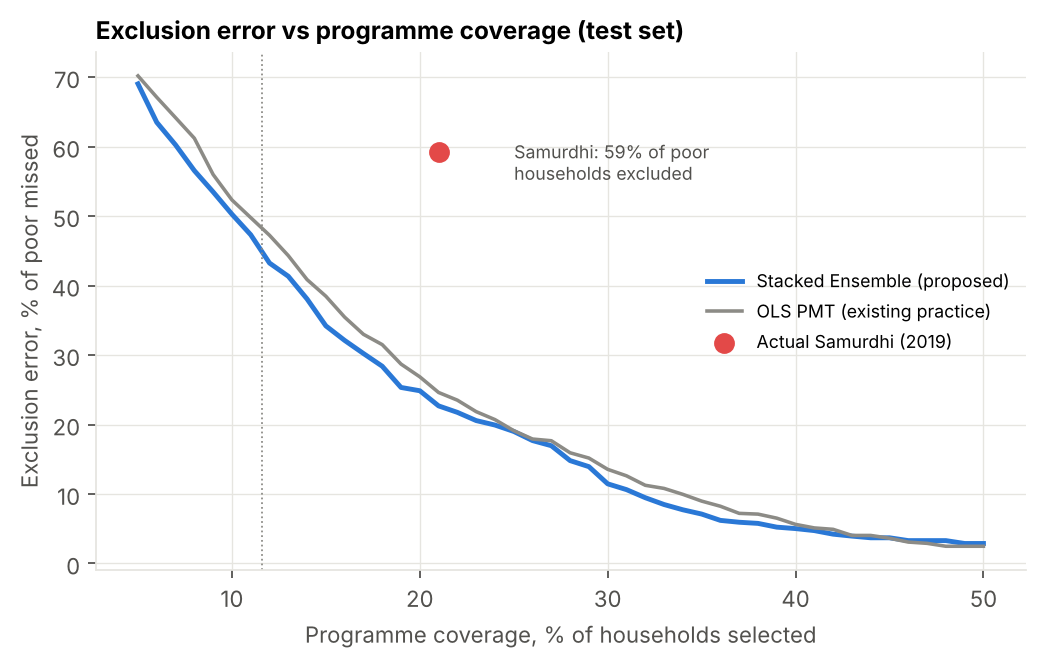

In [29]:
show('fig14_samurdhi_exclusion_curve.png', 720)

### 7.1 How short can the field form be?

In [30]:
pd.read_csv(TAB/'compact_form_ablation.csv')

,n_features,PR_AUC,ROC_AUC
0,10,0.5248,0.8930
1,20,0.5555,0.8952
2,30,0.5653,0.9014
3,45,0.5603,0.9023
4,93,0.5697,0.9015


## 8. Deployment
* `app/app.py` - Streamlit screener (form -> probability, decision, SHAP reasons; batch CSV scoring; model card).
* `Dockerfile`, pinned `requirements.txt`, GitHub Actions CI (`tests/` + Docker build), MLflow tracking (`mlflow ui --backend-store-uri sqlite:///mlflow.db`).

See the report for the full discussion.